
# LankaPrice AI
## Intelligent Food Commodity Price Prediction and Market Analysis in Sri Lanka Using Ensemble and Hybrid Machine Learning

### Project Overview
This project aims to analyse and predict food commodity prices in Sri Lanka using historical market price data.

Multiple ensemble learning algorithms will be implemented and compared, including Random Forest, XGBoost, LightGBM, CatBoost and Stacking.

A hybrid machine learning approach will also be investigated to improve forecasting performance.

### Main Objectives
1. Analyse historical food commodity prices.
2. Perform data preprocessing and exploratory data analysis.
3. Implement Bagging, Boosting and Stacking.
4. Develop a hybrid prediction model.
5. Compare model performance.
6. Build an interactive Streamlit dashboard.


In [ ]:
!pip -q install xgboost lightgbm catboost

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 20)

print("Libraries imported successfully!")
print("LankaPrice AI project started.")


Libraries imported successfully!
LankaPrice AI project started.


In [ ]:

from google.colab import files

uploaded = files.upload()

Saving ganna-food-prices.csv to ganna-food-prices.csv


In [ ]:
filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df.head()

,date,category,item,slug,unit,market,wholesale_today,retail_today,wholesale_yesterday,retail_yesterday
0,2026-11-17,vegetables,Beans,beans,Rs./kg,Pettah,450.0,500.0,450.0,500.0
1,2026-11-17,vegetables,Beans,beans,Rs./kg,Dambulla,450.0,480.0,475.0,505.0
2,2026-11-17,vegetables,Beans,beans,Rs./kg,Narahenpita,NaN,800.0,NaN,700.0
3,2026-11-17,vegetables,Carrot,carrot,Rs./kg,Pettah,500.0,550.0,450.0,500.0
4,2026-11-17,vegetables,Carrot,carrot,Rs./kg,Dambulla,415.0,445.0,440.0,470.0


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 126
Number of columns: 10


In [ ]:
print("Dataset Columns:")
for col in df.columns:
    print(col)

Dataset Columns:
date
category
item
slug
unit
market
wholesale_today
retail_today
wholesale_yesterday
retail_yesterday


In [ ]:
df.info()

print("\nMissing values:")
print(df.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 126 entries, 0 to 125
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 126 non-null    object 
 1   category             126 non-null    object 
 2   item                 126 non-null    object 
 3   slug                 126 non-null    object 
 4   unit                 126 non-null    object 
 5   market               126 non-null    object 
 6   wholesale_today      67 non-null     float64
 7   retail_today         99 non-null     float64
 8   wholesale_yesterday  67 non-null     float64
 9   retail_yesterday     100 non-null    float64
dtypes: float64(4), object(6)
memory usage: 10.0+ KB

Missing values:
date                    0
category                0
item                    0
slug                    0
unit                    0
market                  0
wholesale_today        59
retail_today           27
wholesale_yesterd

In [ ]:

print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [ ]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,126,1,2026-11-17,126,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,126,5,other,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN
item,126,42,Beans,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
slug,126,42,beans,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
unit,126,4,Rs./kg,111,NaN,NaN,NaN,NaN,NaN,NaN,NaN
market,126,6,Narahenpita,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wholesale_today,67.0,NaN,NaN,NaN,561.58209,460.976932,41.0,221.0,415.0,846.5,1963.0
retail_today,99.0,NaN,NaN,NaN,640.505051,613.236768,42.0,237.5,400.0,720.0,2500.0
wholesale_yesterday,67.0,NaN,NaN,NaN,555.955224,455.703234,40.0,222.5,440.0,775.0,1963.0
retail_yesterday,100.0,NaN,NaN,NaN,650.42,608.0522,40.0,240.0,370.0,785.0,2500.0


In [ ]:
import requests
import zipfile
import io
import os

url = "https://microdata.worldbank.org/api/downloads/download/LKA_2021_RTFP_v02_M/361725?filename=LKA_RTFP_mkt_2007_2026-11-17.zip"

response = requests.get(url, timeout=120)
response.raise_for_status()

if not response.content.startswith(b"PK"):
    raise ValueError("Downloaded file is not a valid ZIP archive.")

os.makedirs("/content/lankaprice_data", exist_ok=True)

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall("/content/lankaprice_data")

print("World Bank dataset downloaded and extracted successfully.")

World Bank dataset downloaded and extracted successfully.


In [ ]:

import pandas as pd
import os

file_path = "/content/lankaprice_data/LKA_RTFP_mkt_2007_2026-11-17.csv"

df = pd.read_csv(file_path)

print("DATASET LOADED SUCCESSFULLY")
print("Dataset shape:", df.shape)

display(df.head())


DATASET LOADED SUCCESSFULLY
Dataset shape: (10516, 46)


,ISO3,country,adm1_name,adm2_name,mkt_name,lat,lon,geo_id,price_date,year,...,l_wheat_flour,c_wheat_flour,inflation_wheat_flour,trust_wheat_flour,o_food_price_index,h_food_price_index,l_food_price_index,c_food_price_index,inflation_food_price_index,trust_food_price_index
0,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,2007-01-01,2007,...,38.75,39.5,NaN,9.9,0.38,0.40,0.38,0.39,NaN,9.9
1,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,2007-02-01,2007,...,39.11,40.0,NaN,9.9,0.39,0.40,0.38,0.39,NaN,9.9
2,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,2007-03-01,2007,...,39.85,40.0,NaN,9.9,0.39,0.40,0.39,0.40,NaN,9.9
3,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,2007-04-01,2007,...,39.71,42.0,NaN,9.9,0.40,0.41,0.39,0.41,NaN,9.9
4,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,2007-05-01,2007,...,41.20,48.5,NaN,9.9,0.41,0.43,0.41,0.43,NaN,9.9


In [ ]:
df["price_date"] = pd.to_datetime(df["price_date"])

print("DATASET INFORMATION")
print("=" * 50)

df.info()

print("\nDATE RANGE")
print("First date:", df["price_date"].min())
print("Last date:", df["price_date"].max())

print("\nMARKET INFORMATION")
print("Number of markets:", df["mkt_name"].nunique())
print("Number of districts:", df["adm2_name"].nunique())

price_columns = [
    "rice_fao",
    "rice_various",
    "wheat_flour",
    "c_rice_fao",
    "c_rice_various",
    "c_wheat_flour",
    "c_food_price_index"
]

print("\nPRICE DATA AVAILABILITY")

for col in price_columns:
    print(
        f"{col}: {df[col].notna().sum()} available, "
        f"{df[col].isna().sum()} missing"
    )

print("\nSAMPLE PRICE DATA")
display(df[["price_date", "mkt_name"] + price_columns].head(10))

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10516 entries, 0 to 10515
Data columns (total 46 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   ISO3                        10516 non-null  object        
 1   country                     10516 non-null  object        
 2   adm1_name                   10516 non-null  object        
 3   adm2_name                   10516 non-null  object        
 4   mkt_name                    10516 non-null  object        
 5   lat                         10277 non-null  float64       
 6   lon                         10277 non-null  float64       
 7   geo_id                      10516 non-null  object        
 8   price_date                  10516 non-null  datetime64[ns]
 9   year                        10516 non-null  int64         
 10  month                       10516 non-null  int64         
 11  currency                    10516 

,price_date,mkt_name,rice_fao,rice_various,wheat_flour,c_rice_fao,c_rice_various,c_wheat_flour,c_food_price_index
0,2007-01-01,Ampara,NaN,33.5,39.5,31.45,33.5,39.5,0.39
1,2007-02-01,Ampara,NaN,33.5,40.0,31.49,33.5,40.0,0.39
2,2007-03-01,Ampara,NaN,34.5,40.0,32.31,34.5,40.0,0.40
3,2007-04-01,Ampara,NaN,35.0,42.0,32.85,35.0,42.0,0.41
4,2007-05-01,Ampara,NaN,35.0,48.5,33.49,35.0,48.5,0.43
5,2007-06-01,Ampara,NaN,37.5,47.0,35.65,37.5,47.0,0.45
6,2007-07-01,Ampara,NaN,38.5,55.0,37.06,38.5,55.0,0.48
7,2007-08-01,Ampara,NaN,38.5,55.0,37.07,38.5,55.0,0.48
8,2007-09-01,Ampara,NaN,40.0,57.0,37.47,40.0,57.0,0.50
9,2007-10-01,Ampara,NaN,40.0,65.5,41.24,40.0,65.5,0.54


In [ ]:
target = "c_rice_various"

print("TARGET VARIABLE:", target)
print("=" * 50)

print("\nPrice Statistics")
display(df[target].describe())

print("\nRecords Per Market")
market_summary = df.groupby("mkt_name")[target].agg(
    ["count", "min", "max", "mean"]
)

print("Number of markets:", len(market_summary))
print("Records per market:", market_summary["count"].unique())

display(market_summary.head(10))

duplicates = df.duplicated(
    subset=["mkt_name", "price_date"]
).sum()

print("\nDuplicate market-month records:", duplicates)

print("\nSpatial Interpolation Distribution")
display(df["spatially_interpolated"].value_counts(dropna=False))

print("\nZero or negative prices:", (df[target] <= 0).sum())
print("Missing target values:", df[target].isna().sum())

TARGET VARIABLE: c_rice_various

Price Statistics


,c_rice_various
count,10516.000000
mean,117.364575
std,67.577247
min,22.260000
25%,68.197500
50%,87.065000
75%,156.145000
max,290.000000



Records Per Market
Number of markets: 44
Records per market: [239]


,count,min,max,mean
mkt_name,,,,
Ampara,239,33.50,252.18,112.219833
Anuradhapura,239,42.00,270.57,118.377950
Badulla,239,39.98,262.89,116.012008
Bandarawela,239,41.00,268.56,118.019916
Batticaloa,239,33.50,256.75,114.413933
Colombo City,239,35.12,252.08,111.447699
Dammbagalla,239,43.32,271.34,119.755983
Dehiattakandiya,239,40.82,275.16,118.839121
Economic Centre - Peliyagoda,239,37.58,250.59,113.578410



Duplicate market-month records: 0

Spatial Interpolation Distribution


,count
spatially_interpolated,
0,10516



Zero or negative prices: 0
Missing target values: 0


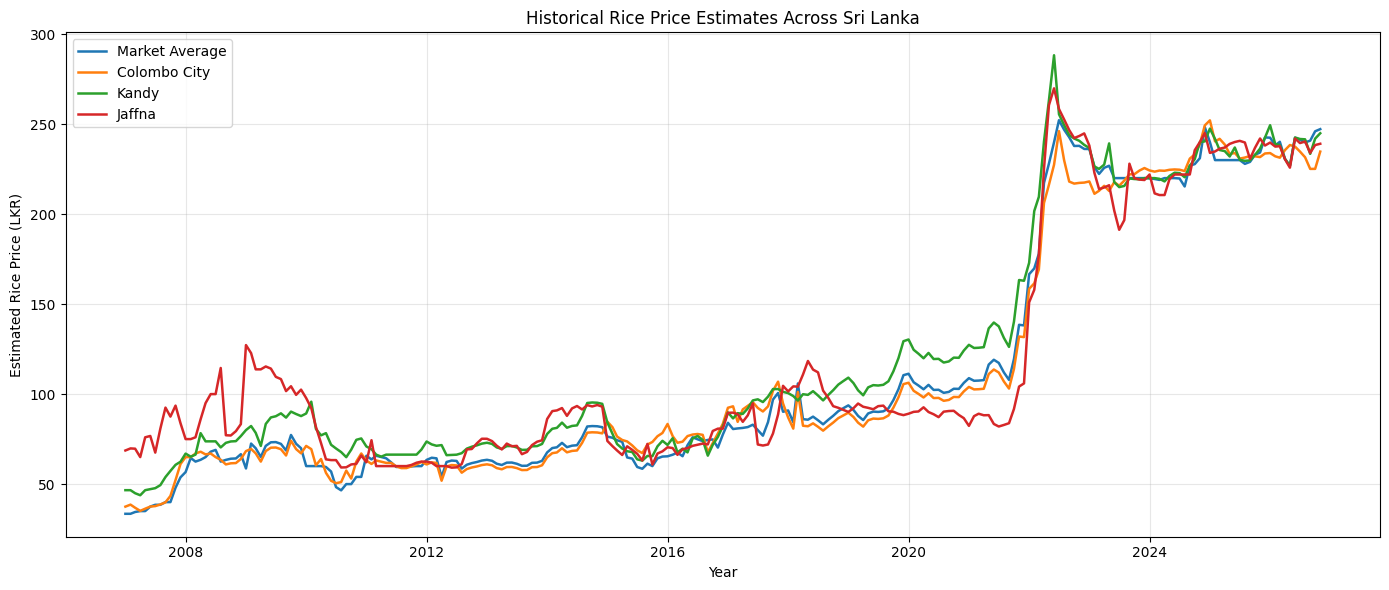

In [ ]:
import matplotlib.pyplot as plt

df = df.sort_values(
    ["mkt_name", "price_date"]
).copy()

selected_markets = [
    "Market Average",
    "Colombo City",
    "Kandy",
    "Jaffna"
]

plt.figure(figsize=(14, 6))

for market in selected_markets:
    market_data = df[df["mkt_name"] == market]

    plt.plot(
        market_data["price_date"],
        market_data["c_rice_various"],
        label=market,
        linewidth=1.8
    )

plt.title("Historical Rice Price Estimates Across Sri Lanka")
plt.xlabel("Year")
plt.ylabel("Estimated Rice Price (LKR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:

df_all_markets = df.copy()

df_all_markets["price_date"] = pd.to_datetime(
    df_all_markets["price_date"]
)

df_all_markets = df_all_markets[
    df_all_markets["mkt_name"] != "Market Average"
].copy()

df_all_markets = df_all_markets.sort_values(
    ["mkt_name", "price_date"]
).copy()

target = "c_rice_various"

df_all_markets["year"] = df_all_markets["price_date"].dt.year
df_all_markets["month"] = df_all_markets["price_date"].dt.month
for lag in [1, 2, 3, 6, 12]:
    df_all_markets[f"lag_{lag}"] = (
        df_all_markets.groupby("mkt_name")[target]
        .shift(lag)
    )

df_all_markets["rolling_mean_3"] = (
    df_all_markets.groupby("mkt_name")[target]
    .transform(lambda x: x.shift(1).rolling(3).mean())
)

df_all_markets["rolling_mean_6"] = (
    df_all_markets.groupby("mkt_name")[target]
    .transform(lambda x: x.shift(1).rolling(6).mean())
)

feature_columns = [
    "lag_1", "lag_2", "lag_3",
    "lag_6", "lag_12",
    "rolling_mean_3", "rolling_mean_6"
]

df_all_markets = df_all_markets.dropna(
    subset=feature_columns
).copy()

print("FEATURE ENGINEERING COMPLETED")
print("=" * 50)

print("Final dataset shape:", df_all_markets.shape)
print("Number of individual markets:",
      df_all_markets["mkt_name"].nunique())

print("\nRecords per market:")
display(df_all_markets["mkt_name"].value_counts())

print("\nMissing feature values:",
      df_all_markets[feature_columns].isnull().sum().sum())

print("\nFirst 5 records:")
display(
    df_all_markets[
        ["price_date", "mkt_name", target] + feature_columns
    ].head()
)


FEATURE ENGINEERING COMPLETED
Final dataset shape: (9761, 53)
Number of individual markets: 43

Records per market:


,count
mkt_name,
Ampara,227
Anuradhapura,227
Badulla,227
Bandarawela,227
Batticaloa,227
...,...
Rathnapura,227
Thambuttegama,227
Tissamaharama,227



Missing feature values: 0

First 5 records:


,price_date,mkt_name,c_rice_various,lag_1,lag_2,lag_3,lag_6,lag_12,rolling_mean_3,rolling_mean_6
12,2008-01-01,Ampara,56.67,53.76,48.00,40.00,38.5,33.5,47.253333,43.126667
13,2008-02-01,Ampara,64.50,56.67,53.76,48.00,38.5,33.5,52.810000,46.155000
14,2008-03-01,Ampara,62.50,64.50,56.67,53.76,40.0,34.5,58.310000,50.488333
15,2008-04-01,Ampara,63.50,62.50,64.50,56.67,40.0,35.0,61.223333,54.238333
16,2008-05-01,Ampara,65.00,63.50,62.50,64.50,48.0,35.0,63.500000,58.155000


In [ ]:
import pandas as pd

fresh_dataset = pd.read_csv(
    "/content/lankaprice_data/LKA_RTFP_mkt_2007_2026-11-17.csv"
)

fresh_dataset["price_date"] = pd.to_datetime(
    fresh_dataset["price_date"]
)

fresh_dataset = fresh_dataset[
    fresh_dataset["mkt_name"] != "Market Average"
].copy()

fresh_dataset = fresh_dataset.sort_values(
    ["mkt_name", "price_date"]
).copy()

fresh_dataset["year"] = fresh_dataset["price_date"].dt.year
fresh_dataset["month"] = fresh_dataset["price_date"].dt.month

for lag in [1, 2, 3, 6, 12]:
    fresh_dataset[f"lag_{lag}"] = (
        fresh_dataset.groupby("mkt_name")["c_rice_various"].shift(lag)
    )

for window in [3, 6]:
    fresh_dataset[f"rolling_mean_{window}"] = (
        fresh_dataset.groupby("mkt_name")["c_rice_various"]
        .transform(lambda x: x.shift(1).rolling(window).mean())
    )

required_columns = [
    "mkt_name",
    "year",
    "month",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_6",
    "lag_12",
    "rolling_mean_3",
    "rolling_mean_6",
    "c_rice_various"
]

fresh_dataset = fresh_dataset.dropna(
    subset=required_columns
).copy()

print("FEATURE ENGINEERING COMPLETED")
print("Dataset shape:", fresh_dataset.shape)
print("Number of markets:", fresh_dataset["mkt_name"].nunique())

print("\nRecords per market:")
print(fresh_dataset.groupby("mkt_name").size().describe())

display(fresh_dataset.head())

FEATURE ENGINEERING COMPLETED
Dataset shape: (9761, 53)
Number of markets: 43

Records per market:
count     43.0
mean     227.0
std        0.0
min      227.0
25%      227.0
50%      227.0
75%      227.0
max      227.0
dtype: float64


,ISO3,country,adm1_name,adm2_name,mkt_name,lat,lon,geo_id,price_date,year,...,c_food_price_index,inflation_food_price_index,trust_food_price_index,lag_1,lag_2,lag_3,lag_6,lag_12,rolling_mean_3,rolling_mean_6
12,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,2008-01-01,2008,...,0.74,90.19,9.9,53.76,48.00,40.00,38.5,33.5,47.253333,43.126667
13,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,2008-02-01,2008,...,0.76,96.14,9.9,56.67,53.76,48.00,38.5,33.5,52.810000,46.155000
14,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,2008-03-01,2008,...,0.74,87.69,9.9,64.50,56.67,53.76,40.0,34.5,58.310000,50.488333
15,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,2008-04-01,2008,...,0.75,83.58,9.9,62.50,64.50,56.67,40.0,35.0,61.223333,54.238333
16,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,2008-05-01,2008,...,0.76,74.82,9.9,63.50,62.50,64.50,48.0,35.0,63.500000,58.155000


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np


In [ ]:
fresh_dataset = fresh_dataset.sort_values(
    ["price_date", "mkt_name"]
).copy()

unique_dates = sorted(fresh_dataset["price_date"].unique())

split_index = int(len(unique_dates) * 0.80)
split_date = unique_dates[split_index]

train_data = fresh_dataset[
    fresh_dataset["price_date"] < split_date
].copy()

test_data = fresh_dataset[
    fresh_dataset["price_date"] >= split_date
].copy()

features = [
    "mkt_name", "year", "month",
    "lag_1", "lag_2", "lag_3",
    "lag_6", "lag_12",
    "rolling_mean_3", "rolling_mean_6"
]

target = "c_rice_various"

X_train = train_data[features]
X_test = test_data[features]

y_train = train_data[target]
y_test = test_data[target]

print("TRAIN-TEST SPLIT COMPLETED")
print("=" * 40)
print("Split date:", split_date)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print("Training markets:", train_data["mkt_name"].nunique())
print("Testing markets:", test_data["mkt_name"].nunique())

TRAIN-TEST SPLIT COMPLETED
Split date: 2023-02-01 00:00:00
X_train: (7783, 10)
X_test: (1978, 10)
y_train: (7783,)
y_test: (1978,)
Training markets: 43
Testing markets: 43


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("market", OneHotEncoder(handle_unknown="ignore"),
         ["mkt_name"])
    ],
    remainder="passthrough"
)

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training Random Forest model...")

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


Training Random Forest model...
Random Forest training completed!


In [ ]:
rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

print("RANDOM FOREST EVALUATION RESULTS")
print("=" * 50)

print(f"MAE  : {rf_mae:.4f}")
print(f"RMSE : {rf_rmse:.4f}")
print(f"R2   : {rf_r2:.4f}")

results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": rf_predictions
})

display(results.head(10))


RANDOM FOREST EVALUATION RESULTS
MAE  : 7.4735
RMSE : 9.4045
R2   : 0.1979


,Actual Price,Predicted Price
0,226.10,235.589044
1,231.19,236.614293
2,220.38,232.259239
3,217.53,232.333464
4,229.01,236.824502
5,211.29,220.243002
6,221.08,231.699828
7,227.79,236.626062
8,221.68,231.736193
9,229.53,237.082214


In [ ]:
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()
importances = rf_model.named_steps["regressor"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

,Feature,Importance
43,remainder__year,5.963890e-01
45,remainder__lag_1,2.197543e-01
50,remainder__rolling_mean_3,1.616400e-01
47,remainder__lag_3,1.201805e-02
44,remainder__month,3.400248e-03
51,remainder__rolling_mean_6,2.591689e-03
48,remainder__lag_6,1.544999e-03
49,remainder__lag_12,1.508449e-03
46,remainder__lag_2,8.837970e-04
5,market__mkt_name_Colombo City,4.161118e-05


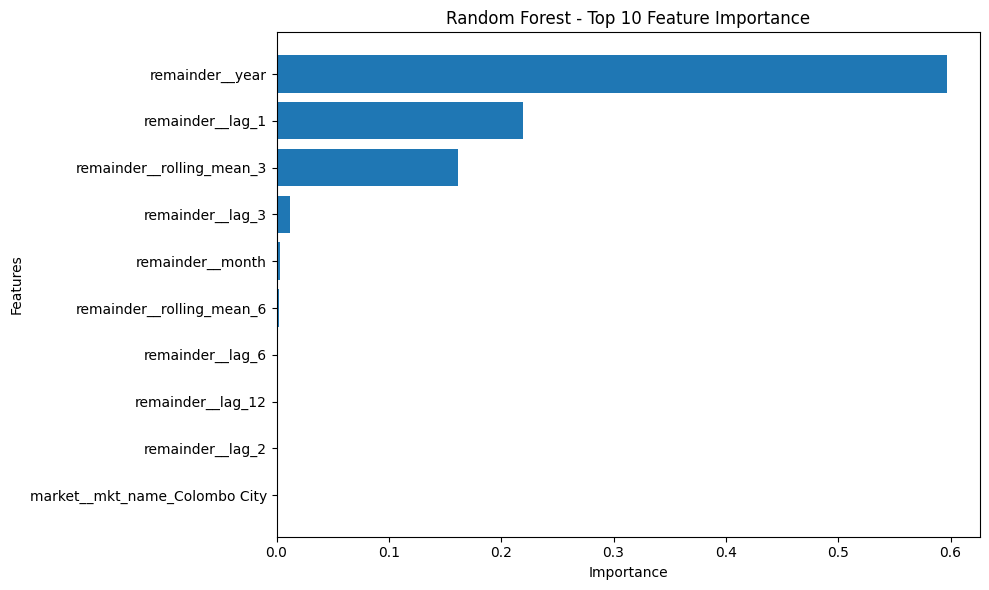

In [ ]:
import matplotlib.pyplot as plt

top_features = importance_df.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Random Forest - Top 10 Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBRegressor

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [ ]:
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        objective="reg:squarederror",
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

print("XGBoost model training completed!")

XGBoost model training completed!


In [ ]:
xgb_predictions = xgb_model.predict(X_test)

xgb_mae = mean_absolute_error(y_test, xgb_predictions)

xgb_rmse = np.sqrt(
    mean_squared_error(y_test, xgb_predictions)
)

xgb_r2 = r2_score(y_test, xgb_predictions)

print("XGBOOST EVALUATION RESULTS")
print("=" * 40)
print(f"MAE  : {xgb_mae:.4f}")
print(f"RMSE : {xgb_rmse:.4f}")
print(f"R2   : {xgb_r2:.4f}")

xgb_results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": xgb_predictions
})

display(xgb_results.head(10))

XGBOOST EVALUATION RESULTS
MAE  : 12.0185
RMSE : 15.1291
R2   : -1.0759


,Actual Price,Predicted Price
0,226.10,234.243317
1,231.19,236.530350
2,220.38,234.425262
3,217.53,234.181610
4,229.01,235.706497
5,211.29,221.632034
6,221.08,230.951599
7,227.79,235.530792
8,221.68,232.778152
9,229.53,236.772339


In [ ]:
!pip install lightgbm

In [ ]:
from lightgbm import LGBMRegressor

print("LightGBM imported successfully!")

LightGBM imported successfully!


In [ ]:
lgbm_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        num_leaves=20,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    ))
])

lgbm_model.fit(X_train, y_train)

print("LightGBM model training completed!")

LightGBM model training completed!


In [ ]:
lgbm_predictions = lgbm_model.predict(X_test)

lgbm_mae = mean_absolute_error(y_test, lgbm_predictions)

lgbm_rmse = np.sqrt(
    mean_squared_error(y_test, lgbm_predictions)
)

lgbm_r2 = r2_score(y_test, lgbm_predictions)


print("LIGHTGBM EVALUATION RESULTS")
print("=" * 40)
print(f"MAE  : {lgbm_mae:.4f}")
print(f"RMSE : {lgbm_rmse:.4f}")
print(f"R2   : {lgbm_r2:.4f}")

lgbm_results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": lgbm_predictions
})

display(lgbm_results.head(10))

LIGHTGBM EVALUATION RESULTS
MAE  : 10.4455
RMSE : 13.2750
R2   : -0.5983


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Actual Price,Predicted Price
0,226.10,234.005331
1,231.19,235.550810
2,220.38,233.880767
3,217.53,234.073729
4,229.01,235.658522
5,211.29,219.877217
6,221.08,231.383967
7,227.79,234.620417
8,221.68,233.076315
9,229.53,235.626672


In [ ]:
!pip install catboost

In [ ]:
from catboost import CatBoostRegressor

print("CatBoost imported successfully!")

CatBoost imported successfully!


In [ ]:
cat_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", CatBoostRegressor(
        iterations=300,
        learning_rate=0.05,
        depth=5,
        loss_function="RMSE",
        random_seed=42,
        verbose=0
    ))
])

# Train the CatBoost model
cat_model.fit(X_train, y_train)

print("CatBoost model training completed!")

CatBoost model training completed!


In [ ]:
# Make predictions
cat_predictions = cat_model.predict(X_test)

# Calculate evaluation metrics
cat_mae = mean_absolute_error(y_test, cat_predictions)

cat_rmse = np.sqrt(
    mean_squared_error(y_test, cat_predictions)
)

cat_r2 = r2_score(y_test, cat_predictions)

# Display results
print("CATBOOST EVALUATION RESULTS")
print("=" * 40)
print(f"MAE  : {cat_mae:.4f}")
print(f"RMSE : {cat_rmse:.4f}")
print(f"R2   : {cat_r2:.4f}")

# Actual vs predicted prices
cat_results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": cat_predictions
})

display(cat_results.head(10))

CATBOOST EVALUATION RESULTS
MAE  : 13.9544
RMSE : 17.0704
R2   : -1.6428


,Actual Price,Predicted Price
0,226.10,237.467683
1,231.19,239.821407
2,220.38,238.405426
3,217.53,238.405426
4,229.01,239.821407
5,211.29,229.164451
6,221.08,235.274783
7,227.79,238.702592
8,221.68,237.634686
9,229.53,239.821407


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone

print("Stacking tools imported successfully!")

Stacking tools imported successfully!


In [ ]:
# Define the base models for stacking
base_models = {
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "LightGBM": lgbm_model,
    "CatBoost": cat_model
}

print("Base models selected for stacking:")
for name in base_models:
    print("-", name)

Base models selected for stacking:
- Random Forest
- XGBoost
- LightGBM
- CatBoost


In [ ]:
train_dates = train_data["price_date"].reset_index(drop=True)
unique_train_dates = np.sort(train_dates.unique())

tscv = TimeSeriesSplit(n_splits=3)

oof_predictions = np.full(
    (len(X_train), len(base_models)),
    np.nan
)

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(unique_train_dates), start=1
):
    fold_train_dates = unique_train_dates[train_idx]
    fold_val_dates = unique_train_dates[val_idx]

    train_pos = np.flatnonzero(
        train_dates.isin(fold_train_dates).to_numpy()
    )
    val_pos = np.flatnonzero(
        train_dates.isin(fold_val_dates).to_numpy()
    )

    print(f"Processing Fold {fold}...")

    for model_idx, (name, model) in enumerate(base_models.items()):
        fold_model = clone(model)

        fold_model.fit(
            X_train.iloc[train_pos],
            y_train.iloc[train_pos]
        )

        oof_predictions[val_pos, model_idx] = (
            fold_model.predict(X_train.iloc[val_pos])
        )

    print(f"Fold {fold} completed!")

valid_rows = ~np.isnan(oof_predictions).any(axis=1)

X_meta_train = oof_predictions[valid_rows]
y_meta_train = y_train.iloc[np.where(valid_rows)[0]]

print("\nStacking training predictions completed!")
print("Meta-training shape:", X_meta_train.shape)
print("Meta-target shape:", y_meta_train.shape)

Processing Fold 1...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Fold 1 completed!
Processing Fold 2...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Fold 2 completed!
Processing Fold 3...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Fold 3 completed!

Stacking training predictions completed!
Meta-training shape: (5805, 4)
Meta-target shape: (5805,)


In [ ]:
# Create the final meta-model
meta_model = Ridge(alpha=1.0)

# Train using out-of-fold predictions
meta_model.fit(X_meta_train, y_meta_train)

print("Stacking meta-model training completed!")

# Show the contribution learned for each base model
meta_weights = pd.DataFrame({
    "Base Model": list(base_models.keys()),
    "Weight": meta_model.coef_
})

display(meta_weights)

Stacking meta-model training completed!


,Base Model,Weight
0,Random Forest,5.012609
1,XGBoost,-4.265076
2,LightGBM,0.494643
3,CatBoost,0.289185


In [ ]:
# Generate predictions from all four base models
test_base_predictions = np.column_stack([
    model.predict(X_test)
    for model in base_models.values()
])

# Generate final stacking predictions
stacking_predictions = meta_model.predict(
    test_base_predictions
)

# Calculate evaluation metrics
stacking_mae = mean_absolute_error(
    y_test, stacking_predictions
)

stacking_rmse = np.sqrt(
    mean_squared_error(y_test, stacking_predictions)
)

stacking_r2 = r2_score(
    y_test, stacking_predictions
)

# Display results
print("STACKING MODEL EVALUATION RESULTS")
print("=" * 45)
print(f"MAE  : {stacking_mae:.4f}")
print(f"RMSE : {stacking_rmse:.4f}")
print(f"R2   : {stacking_r2:.4f}")

# Actual vs predicted prices
stacking_results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": stacking_predictions
})

display(stacking_results.head(10))

STACKING MODEL EVALUATION RESULTS
MAE  : 71.1384
RMSE : 75.9178
R2   : -51.2713


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Actual Price,Predicted Price
0,226.10,328.908114
1,231.19,325.738041
2,220.38,311.650660
3,217.53,313.157363
4,229.01,330.358809
5,211.29,296.382932
6,221.08,321.521627
7,227.79,329.276464
8,221.68,315.433078
9,229.53,327.088967


In [ ]:
# Average rice price by year in training data
print("TRAINING DATA: YEARLY PRICE TREND")

display(
    train_data.groupby(
        train_data["price_date"].dt.year
    )["c_rice_various"]
    .agg(["mean", "median", "count"])
    .round(2)
)

# Average rice price by year in testing data
print("\nTESTING DATA: YEARLY PRICE TREND")

display(
    test_data.groupby(
        test_data["price_date"].dt.year
    )["c_rice_various"]
    .agg(["mean", "median", "count"])
    .round(2)
)

TRAINING DATA: YEARLY PRICE TREND


,mean,median,count
price_date,,,
2008,67.58,68.46,516
2009,79.88,80.98,516
2010,69.36,67.53,516
2011,63.82,63.45,516
2012,65.04,65.04,516
2013,67.23,67.84,516
2014,82.38,80.94,516
2015,68.65,68.12,516
2016,73.18,72.78,516



TESTING DATA: YEARLY PRICE TREND


,mean,median,count
price_date,,,
2023,219.15,219.32,473
2024,224.56,221.26,516
2025,234.58,233.00,516
2026,238.70,239.81,473


In [ ]:
# Simple average ensemble of four base models

average_predictions = test_base_predictions.mean(axis=1)

average_mae = mean_absolute_error(y_test, average_predictions)
average_rmse = np.sqrt(mean_squared_error(y_test, average_predictions))
average_r2 = r2_score(y_test, average_predictions)

print("SIMPLE AVERAGE ENSEMBLE RESULTS")
print("=" * 40)
print(f"MAE:  {average_mae:.4f}")
print(f"RMSE: {average_rmse:.4f}")
print(f"R2:   {average_r2:.4f}")

SIMPLE AVERAGE ENSEMBLE RESULTS
MAE:  10.6161
RMSE: 13.3047
R2:   -0.6054


In [ ]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

# Create chronological validation folds using complete months
train_dates = train_data["price_date"].reset_index(drop=True)
unique_train_dates = np.sort(train_dates.unique())

time_cv = TimeSeriesSplit(n_splits=3)
cv_splits = []

for train_idx, val_idx in time_cv.split(unique_train_dates):

    fold_train_dates = unique_train_dates[train_idx]
    fold_val_dates = unique_train_dates[val_idx]

    train_positions = np.flatnonzero(
        train_dates.isin(fold_train_dates).to_numpy()
    )

    val_positions = np.flatnonzero(
        train_dates.isin(fold_val_dates).to_numpy()
    )

    cv_splits.append((train_positions, val_positions))


# Random Forest settings to experiment with
rf_parameters = {
    "regressor__n_estimators": [200, 300, 500],
    "regressor__max_depth": [None, 10, 15, 20],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [1, 2, 4],
    "regressor__max_features": ["sqrt", 1.0]
}


# Run hyperparameter tuning
rf_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=rf_parameters,
    n_iter=10,
    scoring="neg_mean_absolute_error",
    cv=cv_splits,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("BEST RANDOM FOREST PARAMETERS:")
print(rf_search.best_params_)

print("\nBEST CROSS-VALIDATION MAE:")
print(round(-rf_search.best_score_, 4))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
BEST RANDOM FOREST PARAMETERS:
{'regressor__n_estimators': 300, 'regressor__min_samples_split': 10, 'regressor__min_samples_leaf': 2, 'regressor__max_features': 1.0, 'regressor__max_depth': 20}

BEST CROSS-VALIDATION MAE:
17.0364


In [ ]:
# Get the best tuned Random Forest model
best_rf_model = rf_search.best_estimator_

# Predict testing data
best_rf_predictions = best_rf_model.predict(X_test)

# Calculate evaluation metrics
best_rf_mae = mean_absolute_error(y_test, best_rf_predictions)
best_rf_rmse = np.sqrt(mean_squared_error(y_test, best_rf_predictions))
best_rf_r2 = r2_score(y_test, best_rf_predictions)

print("TUNED RANDOM FOREST RESULTS")
print("=" * 40)
print(f"MAE:  {best_rf_mae:.4f}")
print(f"RMSE: {best_rf_rmse:.4f}")
print(f"R2:   {best_rf_r2:.4f}")

TUNED RANDOM FOREST RESULTS
MAE:  7.0069
RMSE: 8.8585
R2:   0.2883


,Model,MAE,RMSE,R2
0,Random Forest,7.4735,9.4045,0.1979
1,Tuned Random Forest,7.0069,8.8585,0.2883
2,XGBoost,12.0185,15.1291,-1.0759
3,LightGBM,10.4455,13.2750,-0.5983
4,CatBoost,13.9544,17.0704,-1.6428
5,Simple Average,10.6161,13.3047,-0.6054
6,Stacking,71.1384,75.9178,-51.2713


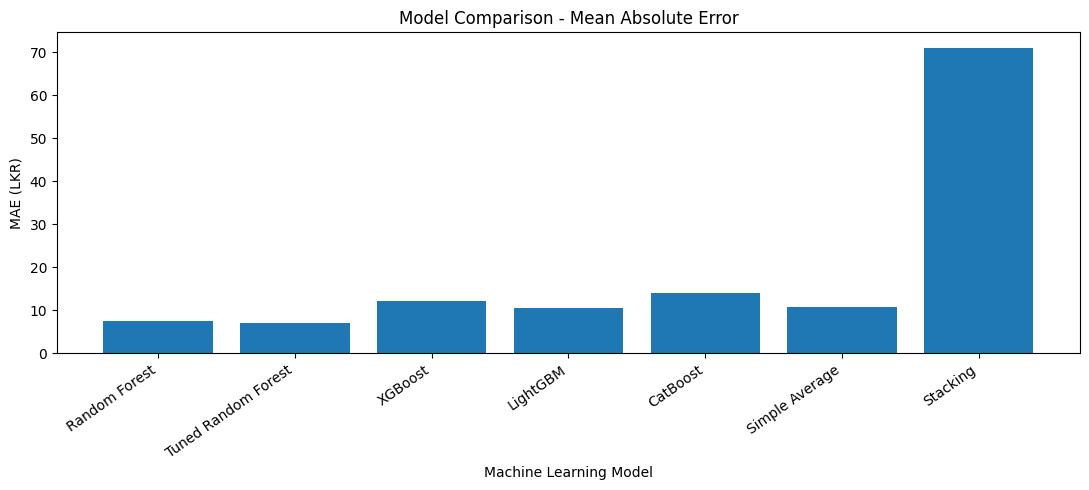

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

comparison_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Tuned Random Forest",
        "XGBoost",
        "LightGBM",
        "CatBoost",
        "Simple Average",
        "Stacking"
    ],
    "MAE": [
        7.4735, 7.0069, 12.0185, 10.4455,
        13.9544, 10.6161, 71.1384
    ],
    "RMSE": [
        9.4045, 8.8585, 15.1291, 13.2750,
        17.0704, 13.3047, 75.9178
    ],
    "R2": [
        0.1979, 0.2883, -1.0759, -0.5983,
        -1.6428, -0.6054, -51.2713
    ]
})

display(comparison_results.round(4))

# Plot MAE comparison
plt.figure(figsize=(11, 5))
plt.bar(comparison_results["Model"], comparison_results["MAE"])
plt.title("Model Comparison - Mean Absolute Error")
plt.xlabel("Machine Learning Model")
plt.ylabel("MAE (LKR)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

print("Number of markets:", train_data["mkt_name"].nunique())

print("Training period:",
      train_data["price_date"].min(),
      "to",
      train_data["price_date"].max())

print("Testing period:",
      test_data["price_date"].min(),
      "to",
      test_data["price_date"].max())

Number of markets: 43
Training period: 2008-01-01 00:00:00 to 2023-01-01 00:00:00
Testing period: 2023-02-01 00:00:00 to 2026-11-01 00:00:00


In [ ]:
# Generate ARIMA predictions for all 43 markets

arima_predictions = []

for market in sorted(test_data["mkt_name"].unique()):

    # Historical prices for this market
    market_train = train_data[
        train_data["mkt_name"] == market
    ].sort_values("price_date")["c_rice_various"]

    # Actual testing prices for this market
    market_test = test_data[
        test_data["mkt_name"] == market
    ].sort_values("price_date")

    # Start with historical training prices
    history = list(market_train)

    for _, row in market_test.iterrows():

        # Fit ARIMA using available historical prices
        arima_model = ARIMA(
            history,
            order=(1, 1, 1)
        )

        arima_fit = arima_model.fit()

        # Predict the next month
        prediction = arima_fit.forecast(steps=1)[0]

        arima_predictions.append({
            "mkt_name": market,
            "price_date": row["price_date"],
            "arima_prediction": prediction
        })

        # Update history with the actual observed price
        history.append(row["c_rice_various"])

print("ARIMA forecasting completed!")

print("Total predictions:", len(arima_predictions))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarnin

ARIMA forecasting completed!
Total predictions: 1978


In [ ]:
# Convert ARIMA predictions into a DataFrame

arima_df = pd.DataFrame(arima_predictions)

# Match ARIMA predictions with actual test prices
arima_evaluation = test_data[
    ["mkt_name", "price_date", "c_rice_various"]
].merge(
    arima_df,
    on=["mkt_name", "price_date"],
    how="inner"
)

# Evaluate ARIMA
arima_mae = mean_absolute_error(
    arima_evaluation["c_rice_various"],
    arima_evaluation["arima_prediction"]
)

arima_rmse = np.sqrt(mean_squared_error(
    arima_evaluation["c_rice_various"],
    arima_evaluation["arima_prediction"]
))

arima_r2 = r2_score(
    arima_evaluation["c_rice_various"],
    arima_evaluation["arima_prediction"]
)

print("ARIMA MODEL RESULTS")
print("=" * 40)
print("Matched predictions:", len(arima_evaluation))
print(f"MAE:  {arima_mae:.4f}")
print(f"RMSE: {arima_rmse:.4f}")
print(f"R2:   {arima_r2:.4f}")

ARIMA MODEL RESULTS
Matched predictions: 1978
MAE:  4.2482
RMSE: 6.4808
R2:   0.6191


In [ ]:
# Create Random Forest prediction dataframe
rf_prediction_df = test_data[
    ["mkt_name", "price_date"]
].copy()

rf_prediction_df["rf_prediction"] = best_rf_predictions

# Combine Random Forest and ARIMA predictions
hybrid_df = rf_prediction_df.merge(
    arima_df,
    on=["mkt_name", "price_date"],
    how="inner"
)

# Add actual prices
hybrid_df = hybrid_df.merge(
    test_data[
        ["mkt_name", "price_date", "c_rice_various"]
    ],
    on=["mkt_name", "price_date"],
    how="inner"
)

# Combine both models equally
hybrid_df["hybrid_prediction"] = (
    0.5 * hybrid_df["rf_prediction"]
    + 0.5 * hybrid_df["arima_prediction"]
)

print("HYBRID MODEL PREDICTIONS GENERATED")
print("Total predictions:", len(hybrid_df))

display(hybrid_df.head(10).round(2))

HYBRID MODEL PREDICTIONS GENERATED
Total predictions: 1978


,mkt_name,price_date,rf_prediction,arima_prediction,c_rice_various,hybrid_prediction
0,Ampara,2023-02-01,235.09,236.31,226.10,235.70
1,Anuradhapura,2023-02-01,236.60,237.93,231.19,237.27
2,Badulla,2023-02-01,232.31,236.59,220.38,234.45
3,Bandarawela,2023-02-01,232.20,233.86,217.53,233.03
4,Batticaloa,2023-02-01,236.79,236.90,229.01,236.85
5,Colombo City,2023-02-01,219.65,218.21,211.29,218.93
6,Dammbagalla,2023-02-01,231.81,232.06,221.08,231.93
7,Dehiattakandiya,2023-02-01,236.73,235.99,227.79,236.36
8,Economic Centre - Peliyagoda,2023-02-01,231.67,233.36,221.68,232.52
9,Economic Centre-Dambulla,2023-02-01,237.05,235.74,229.53,236.40


In [ ]:
# Calculate hybrid model evaluation metrics

hybrid_mae = mean_absolute_error(
    hybrid_df["c_rice_various"],
    hybrid_df["hybrid_prediction"]
)

hybrid_rmse = np.sqrt(mean_squared_error(
    hybrid_df["c_rice_various"],
    hybrid_df["hybrid_prediction"]
))

hybrid_r2 = r2_score(
    hybrid_df["c_rice_various"],
    hybrid_df["hybrid_prediction"]
)

print("HYBRID MODEL RESULTS")
print("=" * 40)
print("Matched predictions:", len(hybrid_df))
print(f"MAE:  {hybrid_mae:.4f}")
print(f"RMSE: {hybrid_rmse:.4f}")
print(f"R2:   {hybrid_r2:.4f}")

HYBRID MODEL RESULTS
Matched predictions: 1978
MAE:  4.8428
RMSE: 6.5573
R2:   0.6100


In [ ]:
# Final comparison of all models

final_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Tuned Random Forest",
        "XGBoost",
        "LightGBM",
        "CatBoost",
        "Simple Average Ensemble",
        "Stacking",
        "ARIMA",
        "Hybrid (RF + ARIMA)"
    ],
    "MAE": [
        7.4735, 7.0069, 12.0185, 10.4455,
        13.9544, 10.6161, 71.1384, 4.2482, 4.8428
    ],
    "RMSE": [
        9.4045, 8.8585, 15.1291, 13.2750,
        17.0704, 13.3047, 75.9178, 6.4808, 6.5573
    ],
    "R2": [
        0.1979, 0.2883, -1.0759, -0.5983,
        -1.6428, -0.6054, -51.2713, 0.6191, 0.6100
    ]
})

display(final_results.round(4))

,Model,MAE,RMSE,R2
0,Random Forest,7.4735,9.4045,0.1979
1,Tuned Random Forest,7.0069,8.8585,0.2883
2,XGBoost,12.0185,15.1291,-1.0759
3,LightGBM,10.4455,13.2750,-0.5983
4,CatBoost,13.9544,17.0704,-1.6428
5,Simple Average Ensemble,10.6161,13.3047,-0.6054
6,Stacking,71.1384,75.9178,-51.2713
7,ARIMA,4.2482,6.4808,0.6191
8,Hybrid (RF + ARIMA),4.8428,6.5573,0.6100


In [ ]:
# Feature importance of the tuned Random Forest

best_rf_regressor = best_rf_model.named_steps["regressor"]

feature_names = (
    best_rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_rf_regressor.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 15 IMPORTANT FEATURES")
display(importance_df.head(15).round(4))

TOP 15 IMPORTANT FEATURES


,Feature,Importance
43,remainder__year,0.5969
45,remainder__lag_1,0.2198
50,remainder__rolling_mean_3,0.1618
47,remainder__lag_3,0.0119
44,remainder__month,0.0034
51,remainder__rolling_mean_6,0.0024
48,remainder__lag_6,0.0014
49,remainder__lag_12,0.0014
46,remainder__lag_2,0.0008
5,market__mkt_name_Colombo City,0.0000


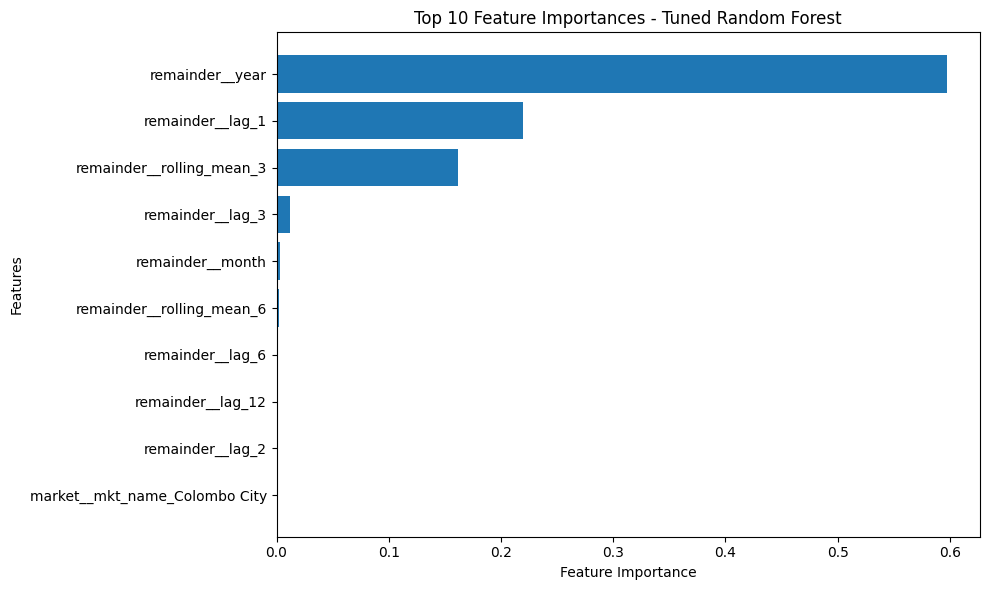

In [ ]:
import matplotlib.pyplot as plt

top_features = importance_df.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 10 Feature Importances - Tuned Random Forest")

plt.tight_layout()
plt.show()

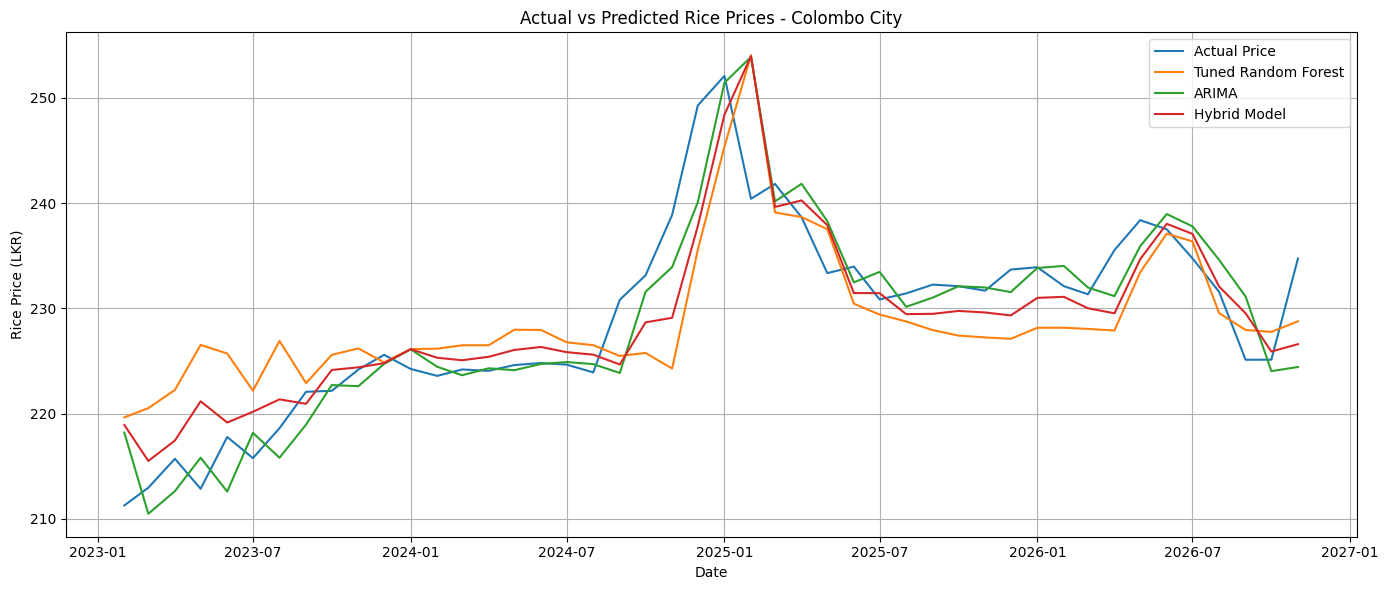

In [ ]:
# Compare actual and predicted prices for one market

selected_market = "Colombo City"

market_results = hybrid_df[
    hybrid_df["mkt_name"] == selected_market
].sort_values("price_date")

plt.figure(figsize=(14, 6))

plt.plot(
    market_results["price_date"],
    market_results["c_rice_various"],
    label="Actual Price"
)

plt.plot(
    market_results["price_date"],
    market_results["rf_prediction"],
    label="Tuned Random Forest"
)

plt.plot(
    market_results["price_date"],
    market_results["arima_prediction"],
    label="ARIMA"
)

plt.plot(
    market_results["price_date"],
    market_results["hybrid_prediction"],
    label="Hybrid Model"
)

plt.title("Actual vs Predicted Rice Prices - Colombo City")
plt.xlabel("Date")
plt.ylabel("Rice Price (LKR)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:

import os
import joblib
import pandas as pd
from sklearn.base import clone

# Reload the original dataset
file_path = "/content/lankaprice_data/LKA_RTFP_mkt_2007_2026-11-17.csv"

df_all_markets = pd.read_csv(file_path)

df_all_markets["price_date"] = pd.to_datetime(
    df_all_markets["price_date"]
)

# Remove aggregate Market Average
df_all_markets = df_all_markets[
    df_all_markets["mkt_name"] != "Market Average"
].copy()

# Sort by market and date
df_all_markets = df_all_markets.sort_values(
    ["mkt_name", "price_date"]
)

# Create date features
df_all_markets["year"] = df_all_markets["price_date"].dt.year
df_all_markets["month"] = df_all_markets["price_date"].dt.month

# Create lag features
for lag in [1, 2, 3, 6, 12]:
    df_all_markets[f"lag_{lag}"] = (
        df_all_markets.groupby("mkt_name")["c_rice_various"].shift(lag)
    )

# Create rolling mean features
for window in [3, 6]:
    df_all_markets[f"rolling_mean_{window}"] = (
        df_all_markets.groupby("mkt_name")["c_rice_various"]
        .transform(lambda x: x.shift(1).rolling(window).mean())
    )

# Define model features and target
features = [
    "mkt_name", "year", "month",
    "lag_1", "lag_2", "lag_3",
    "lag_6", "lag_12",
    "rolling_mean_3", "rolling_mean_6"
]

target = "c_rice_various"

# Remove missing values only from required model columns
df_all_markets = df_all_markets.dropna(
    subset=features + [target]
).copy()

# Check dataset before training
print("FINAL DATASET CHECK")
print("Training records:", len(df_all_markets))
print("Markets:", df_all_markets["mkt_name"].nunique())

assert len(df_all_markets) == 9761, "Unexpected number of records!"
assert df_all_markets["mkt_name"].nunique() == 43, "Expected 43 markets!"

# Create project folder
os.makedirs("lankaprice_models", exist_ok=True)

# Train final tuned Random Forest on all available data
final_rf_model = clone(best_rf_model)

final_rf_model.fit(
    df_all_markets[features],
    df_all_markets[target]
)

# Save final model
joblib.dump(
    final_rf_model,
    "lankaprice_models/final_random_forest.pkl"
)

# Save historical market data
market_history = df_all_markets[
    ["mkt_name", "price_date", "c_rice_various"]
].copy()

market_history.to_csv(
    "lankaprice_models/market_history.csv",
    index=False
)

print("\nFINAL MODEL AND DATA SAVED SUCCESSFULLY")
print("Final training records:", len(df_all_markets))
print("Markets:", df_all_markets["mkt_name"].nunique())
print("Saved files:", os.listdir("lankaprice_models"))


FINAL DATASET CHECK
Training records: 9761
Markets: 43

FINAL MODEL AND DATA SAVED SUCCESSFULLY
Final training records: 9761
Markets: 43
Saved files: ['market_history.csv', 'final_random_forest.pkl']
FINAL DATASET CHECK
Training records: 9761
Markets: 43

FINAL MODEL AND DATA SAVED SUCCESSFULLY
Final training records: 9761
Markets: 43
Saved files: ['market_history.csv', 'final_random_forest.pkl']


In [ ]:
final_metrics = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Tuned Random Forest",
        "XGBoost",
        "LightGBM",
        "CatBoost",
        "Simple Average Ensemble",
        "Stacking",
        "ARIMA",
        "Hybrid (RF + ARIMA)"
    ],
    "MAE": [
        7.4735, 7.0069, 12.0185, 10.4455,
        13.9544, 10.6161, 71.1384, 4.2482, 4.8428
    ],
    "RMSE": [
        9.4045, 8.8585, 15.1291, 13.2750,
        17.0704, 13.3047, 75.9178, 6.4808, 6.5573
    ],
    "R2": [
        0.1979, 0.2883, -1.0759, -0.5983,
        -1.6428, -0.6054, -51.2713, 0.6191, 0.6100
    ]
})

final_metrics.to_csv(
    "lankaprice_models/model_comparison.csv",
    index=False
)

print("MODEL COMPARISON SAVED SUCCESSFULLY")
display(final_metrics)

MODEL COMPARISON SAVED SUCCESSFULLY


,Model,MAE,RMSE,R2
0,Random Forest,7.4735,9.4045,0.1979
1,Tuned Random Forest,7.0069,8.8585,0.2883
2,XGBoost,12.0185,15.1291,-1.0759
3,LightGBM,10.4455,13.2750,-0.5983
4,CatBoost,13.9544,17.0704,-1.6428
5,Simple Average Ensemble,10.6161,13.3047,-0.6054
6,Stacking,71.1384,75.9178,-51.2713
7,ARIMA,4.2482,6.4808,0.6191
8,Hybrid (RF + ARIMA),4.8428,6.5573,0.6100


## References

Andrée, B. P. J. (2021). *Monthly food price estimates by product and market* (Version 2026-11-17). World Bank Microdata Library. Sri Lanka dataset, LKA_2021_RTFP_v02_M.

Dataset DOI: https://doi.org/10.48529/2ZH0-JF55

Dataset source: https://microdata.worldbank.org/catalog/6169

License: Creative Commons Attribution 4.0 International (CC BY 4.0).

## Generative AI Acknowledgement

Generative Artificial Intelligence (GenAI), specifically ChatGPT by OpenAI, was used as an assistance tool during this project.

It was used to support Python code development, debugging, machine learning implementation guidance, Streamlit dashboard design, and explanations of technical concepts.

